In [12]:
import numpy as np
import matplotlib.pyplot as plt



In [13]:
#read data.npy
data = np.load('data.npy')
x = data[0]
y = data[1]

In [14]:
print(f"Data shape: {data.shape}")
print(f"First element of x: {x[0][0]}")
print(f"x shape: {x.shape}")
print(f"y shape: {y.shape}")

Data shape: (2, 100, 1)
First element of x: 0.042828681417311144
x shape: (100, 1)
y shape: (100, 1)


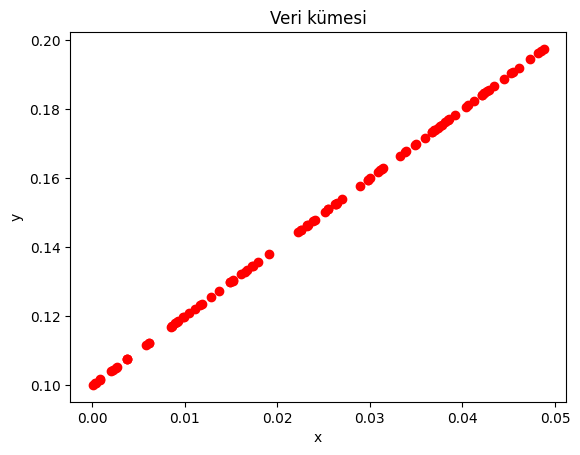

In [15]:
plt.figure()
plt.title('Veri kümesi')
plt.xlabel('x')
plt.ylabel('y')
plt.plot(x, y, 'ro')

In [16]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt


# Load and preprocess data
data = np.load("data.npy")
x, y = data[0], data[1]

# Initialize weights and bias for a single-layer perceptron
input_dim = x.shape[1]  # Number of features
output_dim = 1  # We have one output (regression task)

# Weights and bias initialization (random values)
weights = np.random.randn(input_dim, output_dim) * 0.01
bias = np.zeros((1, 1))

# Sigmoid activation function
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Sigmoid derivative (for backpropagation)
def sigmoid_derivative(x):
    return x * (1 - x)

# Define training parameters
learning_rate = 0.05
epochs = 500000

# Training loop
for epoch in range(epochs):
    # Forward pass
    z = np.dot(x, weights) + bias  # Linear combination
    predictions = sigmoid(z)  # Sigmoid activation
    
    # Compute loss (Mean Squared Error)
    loss = np.mean((predictions - y) ** 2)
    
    # Backward pass
    d_loss = 2 * (predictions - y) # Gradient of Mean Squared Error
    d_predictions = d_loss * sigmoid_derivative(predictions)  # Gradient of sigmoid

    # Update weights and bias using the gradients
    weights -= learning_rate * np.dot(x.T, d_predictions)
    bias -= learning_rate * np.sum(d_predictions, axis=0, keepdims=True)
    
    # Print loss every 500 epochs
    if (epoch + 1) % 1000 == 0:
        print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss}")

# Final weights and biases
print("\nFinal Model Parameters:")
print("Weights:", weights)
print("Bias:", bias)

# Test the model
test_predictions = sigmoid(np.dot(x, weights) + bias)
print("\nPredictions (first 5 samples):", test_predictions[:5].flatten())


Epoch 1000/500000, Loss: 0.0007833129607265994
Epoch 2000/500000, Loss: 0.0007325480407540797
Epoch 3000/500000, Loss: 0.0006850715984781983
Epoch 4000/500000, Loss: 0.0006406818318510327
Epoch 5000/500000, Loss: 0.0005991869878207022
Epoch 6000/500000, Loss: 0.0005604052767203473
Epoch 7000/500000, Loss: 0.0005241647047226443
Epoch 8000/500000, Loss: 0.0004903028410386191
Epoch 9000/500000, Loss: 0.00045866653435848453
Epoch 10000/500000, Loss: 0.00042911159101220703
Epoch 11000/500000, Loss: 0.0004015024254846587
Epoch 12000/500000, Loss: 0.0003757116922606206
Epoch 13000/500000, Loss: 0.0003516199064970698
Epoch 14000/500000, Loss: 0.00032911505971745065
Epoch 15000/500000, Loss: 0.00030809223558463626
Epoch 16000/500000, Loss: 0.0002884532298237264
Epoch 17000/500000, Loss: 0.00027010617751903625
Epoch 18000/500000, Loss: 0.00025296519028778224
Epoch 19000/500000, Loss: 0.00023695000522231595
Epoch 20000/500000, Loss: 0.00022198564698026343
Epoch 21000/500000, Loss: 0.0002080021039

In [17]:
print(f"Epoch {epoch+1}/{epochs}, Loss: {loss}")


Epoch 500000/500000, Loss: 4.022680738674898e-06


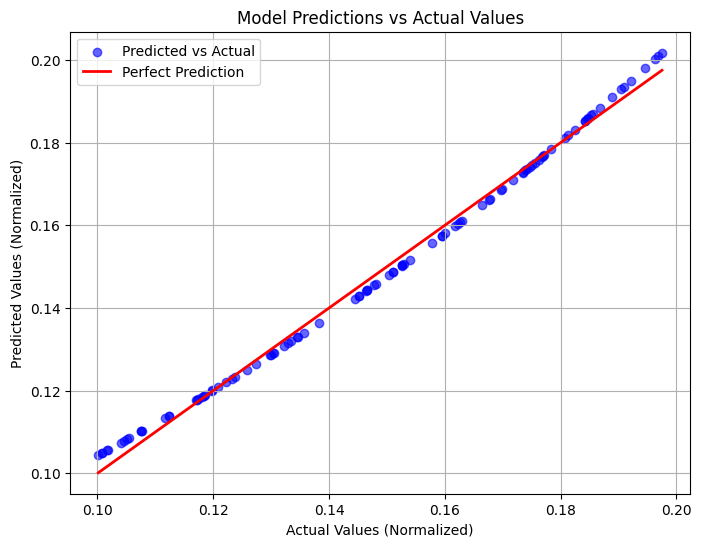

In [18]:
y_pred = sigmoid(weights * x + bias)
# Visualize predictions vs actual values
plt.figure(figsize=(8, 6))
plt.scatter(y, y_pred, color="blue", alpha=0.6, label="Predicted vs Actual")
#plot the perfect prediction line
plt.plot([y.min(), y.max()], [y.min(), y.max()], color="red", linewidth=2, label="Perfect Prediction")
plt.title("Model Predictions vs Actual Values")
plt.xlabel("Actual Values (Normalized)")
plt.ylabel("Predicted Values (Normalized)")
plt.legend()
plt.grid(True)
plt.show()

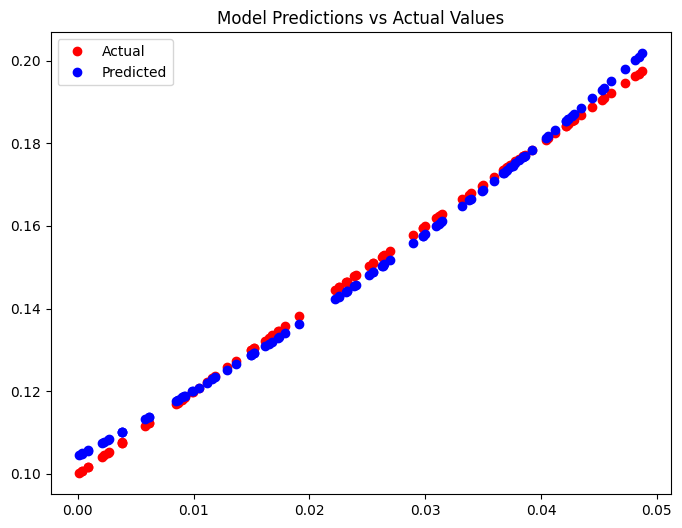

In [19]:
plt.figure(figsize=(8, 6))
plt.title("Model Predictions vs Actual Values")
plt.plot(x, y, 'ro')
plt.plot(x, y_pred, 'bo')
plt.legend(["Actual", "Predicted"])
plt.show()


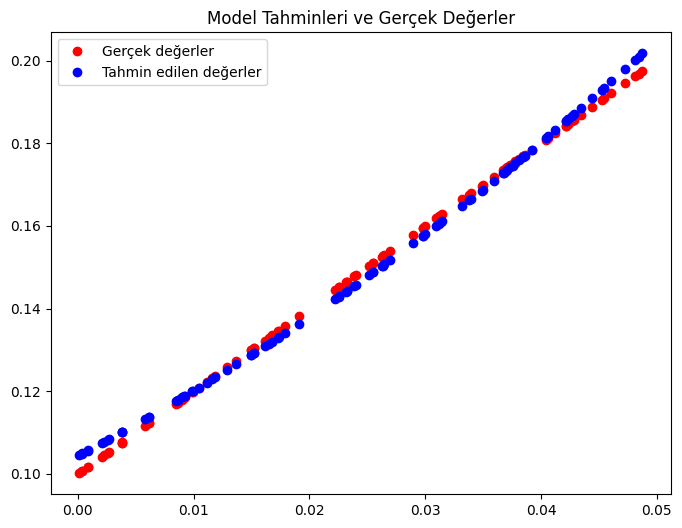

In [20]:
plt.figure(figsize=(8, 6))
plt.title("Model Tahminleri ve Gerçek Değerler")
plt.plot(x, y, 'ro')
plt.plot(x, y_pred, 'bo')
plt.legend(["Gerçek değerler", "Tahmin edilen değerler"])
plt.show()


# Trying with pytorch

In [21]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# Load and preprocess data
data = np.load("data.npy")
x, y = data[0], data[1]


# Convert data to PyTorch tensors
x_tensor = torch.tensor(x, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32)

# Define the Multi-Layer Perceptron (MLP)
class MultiLayerPerceptron(nn.Module):
    def __init__(self, input_dim):
        super(MultiLayerPerceptron, self).__init__()
        # Define layers
        self.fc1 = nn.Linear(input_dim, 1)  # Input layer to hidden layer 1 (64 neurons)
        self.activation = nn.Sigmoid()      # Sigmoid activation for regression output
    
    def forward(self, x):
        x = self.activation(self.fc1(x))   # Apply Sigmoid for output layer
        return x

# Model parameters
input_dim = x.shape[1]  # Number of features
model = MultiLayerPerceptron(input_dim)

# Define loss and optimizer
criterion = nn.MSELoss()  # Mean squared error for regression
optimizer = optim.Adam(model.parameters(), lr=0.001)  # Adam optimizer for better learning

# Training loop
epochs = 500000
for epoch in range(epochs):
    # Forward pass
    predictions = model(x_tensor)
    
    # Compute loss
    loss = criterion(predictions, y_tensor)
    
    # Backward pass and optimization
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    # Print loss every 500 epochs
    if (epoch + 1) % 1000 == 0:
        print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss.item()}")

# Final weights and biases
print("\nFinal Model Parameters:")
for name, param in model.named_parameters():
    print(f"{name}: {param.data}")

# Test the model
with torch.no_grad():
    test_predictions = model(x_tensor)
    print("\nPredictions (first 5 samples):", test_predictions[:5].numpy())


Epoch 1000/500000, Loss: 0.05903216823935509
Epoch 2000/500000, Loss: 0.014456120319664478
Epoch 3000/500000, Loss: 0.0038813287392258644
Epoch 4000/500000, Loss: 0.0015047055203467607
Epoch 5000/500000, Loss: 0.00107746128924191
Epoch 6000/500000, Loss: 0.001008352730423212
Epoch 7000/500000, Loss: 0.0009583617793396115
Epoch 8000/500000, Loss: 0.0008916264632716775
Epoch 9000/500000, Loss: 0.0008112115319818258
Epoch 10000/500000, Loss: 0.0007246914319694042
Epoch 11000/500000, Loss: 0.000638536352198571
Epoch 12000/500000, Loss: 0.0005562983569689095
Epoch 13000/500000, Loss: 0.0004794932610820979
Epoch 14000/500000, Loss: 0.0004086696426384151
Epoch 15000/500000, Loss: 0.0003439858846832067
Epoch 16000/500000, Loss: 0.00028544600354507565
Epoch 17000/500000, Loss: 0.00023298854648601264
Epoch 18000/500000, Loss: 0.00018651792197488248
Epoch 19000/500000, Loss: 0.0001459129125578329
Epoch 20000/500000, Loss: 0.00011102762800874189
Epoch 21000/500000, Loss: 8.168591011781245e-05
Epoc

In [22]:
print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss.item()}")


Epoch 500000/500000, Loss: 4.022680059279082e-06


Model Performance on Training Data:
Mean Squared Error (MSE): 0.0000


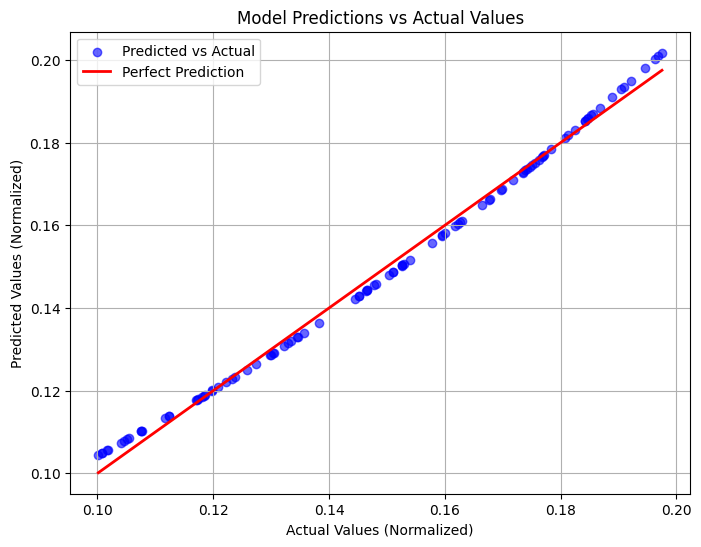

Prediction for first sample: 0.1870
Actual value for first sample: 0.1857


In [23]:
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Evaluate the model on the training data
with torch.no_grad():
    y_pred = model(x_tensor)  # Predictions on the training data
    y_pred_np = y_pred.numpy()  # Convert predictions to NumPy
    y_true_np = y_tensor.numpy()  # Convert actual values to NumPy

# Calculate performance metrics
mse = mean_squared_error(y_true_np, y_pred_np)  # Mean Squared Error
#r2 = r2_score(y_true_np, y_pred_np)            # R-squared score

# Print performance metrics
print("Model Performance on Training Data:")
print(f"Mean Squared Error (MSE): {mse:.4f}")
#print(f"R-squared (R²): {r2:.4f}")

# Visualize predictions vs actual values
plt.figure(figsize=(8, 6))
plt.scatter(y_true_np, y_pred_np, color="blue", alpha=0.6, label="Predicted vs Actual")
#plot the perfect prediction line
plt.plot([y_true_np.min(), y_true_np.max()], [y_true_np.min(), y_true_np.max()], color="red", linewidth=2, label="Perfect Prediction")
plt.title("Model Predictions vs Actual Values")
plt.xlabel("Actual Values (Normalized)")
plt.ylabel("Predicted Values (Normalized)")
plt.legend()
plt.grid(True)
plt.show()

# Example: Testing on a single sample
single_sample = x_tensor[0].unsqueeze(0)  # Select the first sample and add batch dimension
with torch.no_grad():
    single_prediction = model(single_sample)
print(f"Prediction for first sample: {single_prediction.item():.4f}")
print(f"Actual value for first sample: {y_tensor[0].item():.4f}")
